
# Project : Real-Time Agentic RAG (Router + Corrective RAG + Live Web + Cache)
**Domain:** Enterprise Assistant | **Level:** Production Capstone | **Stack:** Python, Groq (gpt-oss-120b), Sentence-Transformers, FAISS, DuckDuckGo search (ddgs)

## Problem statement
A company bot has to answer two kinds of questions: private ones (leave policy, expenses) and live ones (weather, news, sports). Also, sometimes the internal search returns chunks that do not answer the question. A basic RAG bot would still answer from bad chunks and make things up.

In this project the bot first **routes** the question, then **grades** the retrieved chunks, **falls back to web search** if they are not relevant, **checks the answer is grounded** in the context, and uses a **semantic cache** so repeated questions are answered fast.

## What I built
- Router: internal documents vs live web
- Retrieval grader (Corrective RAG): keeps only relevant chunks
- Web fallback with DuckDuckGo (no API key needed)
- Answer generator + groundedness checker with one retry
- Semantic cache (in memory here, Redis in a real production system)
- Test run of 6 questions with route accuracy, latency and cache hit table

## Step 0: Install libraries

In [1]:
!pip install -q openai sentence-transformers faiss-cpu ddgs pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 32.9 MB/s eta 0:00:00


## Step 1: Connect to Groq

In [2]:
import os, json, time, re
from getpass import getpass
from openai import OpenAI

if "GROQ_API_KEY" not in os.environ:
    os.environ["GROQ_API_KEY"] = getpass("Paste your Groq API key here: ")

client = OpenAI(api_key=os.environ["GROQ_API_KEY"], base_url="https://api.groq.com/openai/v1")
MODEL = "openai/gpt-oss-120b"

def call_llm(prompt, system="You are a helpful assistant.", json_mode=False):
    for attempt in range(3):
        try:
            msgs = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
            if json_mode:
                res = client.chat.completions.create(model=MODEL, messages=msgs, temperature=0, response_format={"type": "json_object"})
            else:
                res = client.chat.completions.create(model=MODEL, messages=msgs, temperature=0)
            return (res.choices[0].message.content or "").strip()
        except Exception as e:
            print("LLM error (try", attempt + 1, "):", str(e)[:150])
            time.sleep(6)
    return ""

print(call_llm("Say hello in 5 words"))

Paste your Groq API key here: ··········
Hello there, nice to meet!


## Step 2: Internal knowledge base
Small set of company policy chunks (Northwind Tech). These are the private documents. Everything else the bot has to get from the web.

In [3]:
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

internal_chunks = [
    "Leave policy: every full-time employee gets 24 days of paid annual leave per year. Up to 5 unused days can be carried over. Sick leave is separate at 10 days per year.",
    "Hybrid work: employees come to the office on Tuesday, Wednesday and Thursday. Fully remote work needs written approval from a VP. New joiners get a home office allowance of Rs 15000.",
    "Expense claims must be submitted within 30 days. Receipts are needed above Rs 500. Meals during travel are reimbursed up to Rs 1200 per day. Claims above Rs 10000 need director approval.",
    "Business travel: flights under 6 hours are economy class. Hotel cap is Rs 6000 per night in metro cities and Rs 4000 elsewhere. Book through the travel portal 7 days ahead.",
    "Information security: passwords must be at least 14 characters and multi-factor authentication is mandatory. Security incidents must be reported within 2 hours.",
    "Probation is 6 months. Notice period is 30 days during probation and 60 days after confirmation.",
    "Performance reviews are held twice a year in June and December. Ratings are 1 to 5 and a score of 4 or above makes you eligible for the yearly bonus.",
    "Benefits: health insurance covers employee, spouse and children up to Rs 5 lakh per family. Learning budget is Rs 40000 per year and does not carry over.",
]

embed_model = SentenceTransformer("all-MiniLM-L6-v2")
chunk_vecs = np.array(embed_model.encode(internal_chunks, normalize_embeddings=True), dtype="float32")
index = faiss.IndexFlatIP(chunk_vecs.shape[1])
index.add(chunk_vecs)

def retrieve(question, k=3):
    qv = np.array(embed_model.encode([question], normalize_embeddings=True), dtype="float32")
    scores, ids = index.search(qv, k)
    return [internal_chunks[int(i)] for i in ids[0] if i != -1]

print("chunks indexed:", index.ntotal)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

chunks indexed: 8


## Step 3: The building blocks
- `route_question` - decides internal or web
- `grade_chunks` - asks the LLM yes/no for each chunk, keeps only the relevant ones
- `web_search` - live DuckDuckGo results (if it fails, returns an empty text and the bot says it could not find live info)
- `generate_answer` and `is_grounded` - answer and self check

In [4]:
from ddgs import DDGS

def route_question(question):
    system = "You are a router. Reply with exactly one word: internal or web."
    prompt = "Reply internal if the question is about company policies, employee rules, leave, expenses, travel, security, benefits or HR.\nReply web if it needs live or general public information like weather, news, sports, prices or world facts.\n\nQuestion: " + question
    ans = call_llm(prompt, system).lower()
    if "web" in ans:
        return "web"
    return "internal"

def grade_chunks(question, chunks_list):
    kept = []
    for c in chunks_list:
        prompt = "Question: " + question + "\n\nChunk: " + c + "\n\nDoes this chunk contain the information needed to answer the question? Reply only yes or no."
        ans = call_llm(prompt, "You are a strict grader.").lower()
        if ans.startswith("yes"):
            kept.append(c)
    return kept

def web_search(question, n=3):
    try:
        results = DDGS().text(question, max_results=n)
        text = ""
        for r in results:
            text = text + "- " + r.get("title", "") + ": " + r.get("body", "") + "\n"
        return text
    except Exception as e:
        print("   (web search failed:", str(e)[:80], ")")
        return ""

def generate_answer(question, context, strict=False):
    system = "Answer using only the context. If the context does not have the answer, say you could not find it. Keep it short."
    if strict:
        system = system + " Do not add any fact that is not written in the context."
    return call_llm("CONTEXT:\n" + context + "\n\nQUESTION: " + question, system)

def is_grounded(answer, context):
    prompt = "CONTEXT:\n" + context + "\n\nANSWER:\n" + answer + "\n\nIs every fact in the answer supported by the context? Reply only yes or no."
    return call_llm(prompt, "You are a fact checker.").lower().startswith("yes")

print("route test:", route_question("How many leave days do I get?"), "|", route_question("What is the weather in Delhi today?"))

route test: internal | web


## Step 4: Semantic cache
If a new question means almost the same as an old one (cosine similarity above 0.85), return the old answer directly without calling the LLM. I use a simple list here. In a real system this would be Redis.

In [5]:
cache_vecs = []
cache_answers = []
CACHE_LIMIT = 0.85

def check_cache(question):
    if len(cache_vecs) == 0:
        return None, 0
    qv = np.array(embed_model.encode([question], normalize_embeddings=True), dtype="float32")[0]
    best_score = 0
    best_i = -1
    for i in range(len(cache_vecs)):
        score = float(np.dot(qv, cache_vecs[i]))
        if score > best_score:
            best_score = score
            best_i = i
    if best_score >= CACHE_LIMIT:
        return cache_answers[best_i], best_score
    return None, best_score

def save_to_cache(question, answer):
    qv = np.array(embed_model.encode([question], normalize_embeddings=True), dtype="float32")[0]
    cache_vecs.append(qv)
    cache_answers.append(answer)

print("cache ready")

cache ready


## Step 5: Full pipeline
Flow:
1. Check cache
2. Route
3. If internal: retrieve, grade. If no chunk is relevant, fall back to web (this is the Corrective RAG part)
4. Generate answer
5. Check grounded. If not, regenerate once with a stricter prompt
6. Save to cache

In [6]:
def run_pipeline(question):
    start = time.time()

    cached, sim = check_cache(question)
    if cached is not None:
        return {"route": "cache", "path": "CACHE HIT", "grounded": "-", "seconds": round(time.time() - start, 2), "answer": cached}

    route = route_question(question)
    path = ""
    context = ""

    if route == "internal":
        found = retrieve(question, 3)
        good = grade_chunks(question, found)
        if len(good) > 0:
            context = "\n".join(good)
            path = "internal docs"
        else:
            context = web_search(question)
            path = "internal FAILED -> web fallback"
    else:
        context = web_search(question)
        path = "live web"

    if context.strip() == "":
        answer = "I could not find information for this question."
        grounded = "no context"
    else:
        answer = generate_answer(question, context)
        grounded = is_grounded(answer, context)
        if not grounded:
            answer = generate_answer(question, context, strict=True)
            grounded = is_grounded(answer, context)
            path = path + " (regenerated)"

    save_to_cache(question, answer)
    return {"route": route, "path": path, "grounded": grounded, "seconds": round(time.time() - start, 2), "answer": answer}

r = run_pipeline("How many days of annual leave do I get?")
print(r["path"], "|", r["seconds"], "sec")
print(r["answer"])

internal docs | 2.27 sec
You get 24 days of paid annual leave per year.


## Step 6: Test on 6 questions
Mix of internal, live, a paraphrase of question 1 (should hit the cache), and a policy question that is NOT in my documents (should trigger web fallback).

In [7]:
import pandas as pd

test_questions = [
    ("How many days of annual leave do I get?", "internal"),
    ("What is the hotel limit per night on business trips?", "internal"),
    ("What is the weather forecast for Mumbai today?", "web"),
    ("Who won the most recent IPL final?", "web"),
    ("How many days of annual leave am I entitled to?", "internal"),
    ("What is the company policy on bringing pets to the office?", "internal"),
]

rows = []
route_right = 0
for q, expected in test_questions:
    r = run_pipeline(q)
    if r["route"] == "cache":
        route_used = "cache"
        route_ok = True
    else:
        route_used = r["route"]
        route_ok = r["route"] == expected
    if route_ok:
        route_right = route_right + 1
    rows.append({"question": q, "expected_route": expected, "path": r["path"], "grounded": r["grounded"], "seconds": r["seconds"], "route_ok": route_ok})
    print("Q:", q)
    print("A:", r["answer"][:300])
    print()

results_df = pd.DataFrame(rows)
results_df

Q: How many days of annual leave do I get?
A: You get 24 days of paid annual leave per year.

Q: What is the hotel limit per night on business trips?
A: The hotel limit is Rs 6,000 per night in metro cities and Rs 4,000 per night elsewhere.

Q: What is the weather forecast for Mumbai today?
A: Today in Mumbai it is expected to be hazy and hot with a chance of a p.m. shower, and there is a 39 % chance of rain.

Q: Who won the most recent IPL final?
A: Royal Challengers Bengaluru won the most recent IPL final.

Q: How many days of annual leave am I entitled to?
A: You get 24 days of paid annual leave per year.

Q: What is the company policy on bringing pets to the office?
A: Employees may bring their own pets to the office — provided the animals are not overly fearful, anxious or aggressive toward people or other animals, and the employee follows the policy’s guidelines. Unweaned animals that need frequent feedings require prior permission from the employee’s leader. Vi



,question,expected_route,path,grounded,seconds,route_ok
0,How many days of annual leave do I get?,internal,CACHE HIT,-,0.03,True
1,What is the hotel limit per night on business ...,internal,internal docs,True,2.90,True
2,What is the weather forecast for Mumbai today?,web,live web,True,4.83,True
3,Who won the most recent IPL final?,web,live web,True,2.89,True
4,How many days of annual leave am I entitled to?,internal,CACHE HIT,-,0.02,True
5,What is the company policy on bringing pets to...,internal,internal FAILED -> web fallback,True,4.84,True


## Step 7: Latency chart
Cache hits should be much faster than a full pipeline run.

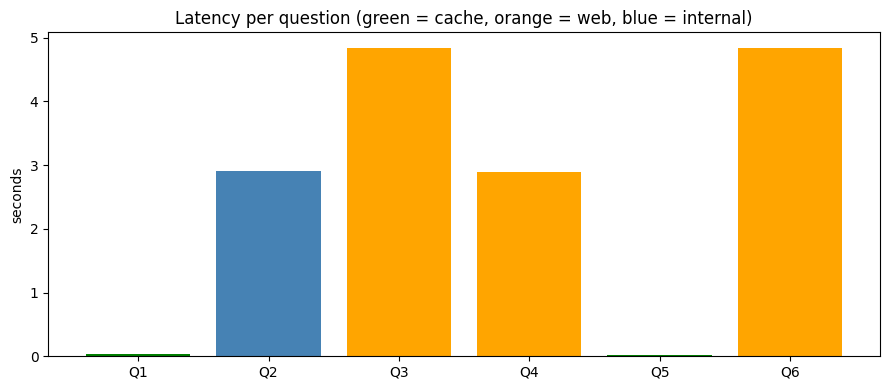

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
labels = ["Q" + str(i + 1) for i in range(len(results_df))]
colors = []
for p in results_df["path"]:
    if "CACHE" in p:
        colors.append("green")
    elif "web" in p:
        colors.append("orange")
    else:
        colors.append("steelblue")
plt.bar(labels, results_df["seconds"], color=colors)
plt.ylabel("seconds")
plt.title("Latency per question (green = cache, orange = web, blue = internal)")
plt.tight_layout()
plt.savefig("latency_chart.png")
plt.show()

## Step 8: Results summary

In [9]:
cache_hits = 0
fallbacks = 0
grounded_count = 0
for i in range(len(results_df)):
    if "CACHE" in results_df["path"][i]:
        cache_hits = cache_hits + 1
    if "FAILED" in results_df["path"][i]:
        fallbacks = fallbacks + 1
    if results_df["grounded"][i] == True:
        grounded_count = grounded_count + 1

print("Routing correct:", route_right, "/", len(test_questions))
print("Cache hits:", cache_hits)
print("Corrective web fallbacks triggered:", fallbacks)
print("Answers passing groundedness check:", grounded_count)
print()
print("Resume bullet (from my own run):")
print("Built a Corrective RAG assistant with LLM routing, chunk grading, DuckDuckGo web fallback, groundedness checking and a semantic cache; on a 6 question test it routed", route_right, "of", len(test_questions), "correctly, triggered", fallbacks, "web fallback(s) when internal documents could not answer, and served", cache_hits, "answer(s) from cache.")

Routing correct: 6 / 6
Cache hits: 2
Corrective web fallbacks triggered: 1
Answers passing groundedness check: 4

Resume bullet (from my own run):
Built a Corrective RAG assistant with LLM routing, chunk grading, DuckDuckGo web fallback, groundedness checking and a semantic cache; on a 6 question test it routed 6 of 6 correctly, triggered 1 web fallback(s) when internal documents could not answer, and served 2 answer(s) from cache.


## Key learnings
- Grading the retrieved chunks is what makes it "corrective", without it the bot answers from wrong chunks
- The router is just one small LLM call but it saves a lot of time and wrong answers
- A semantic cache needs a good similarity limit: too low gives wrong answers, too high never hits
- Groundedness check adds extra LLM calls (more latency), so it is a trade-off between speed and safety
- Web search can fail, so the pipeline must handle empty results without crashing
- All numbers above come from a very small 6 question test, so treat them as a demo, not a benchmark

## Skills shown
Agentic RAG, Semantic routing, Corrective RAG (CRAG), LLM-as-a-grader, Hallucination checking, Semantic caching, Web search integration, FAISS, Groq API

## Ideas to extend
- Swap the in-memory cache for Redis
- Turn the pipeline into a LangGraph graph with nodes and edges
- Add LangSmith or Arize Phoenix tracing
- Wrap it in a Streamlit or FastAPI app

---
**Built by Akshat Kesharwani** | Portfolio: https://akshatkesharwani-info.github.io/ | GitHub: https://github.com/akshatkesharwani-info

Project idea taken from the Dipanshu.Decoded Agentic AI handbook. I rewrote the code to run free on Groq and added my own test questions and evaluation.